# Khám phá dữ liệu AI: VAIPE và PharmaVision

Notebook **chỉ đọc dữ liệu**. Mở từ thư mục dự án, `model/` hoặc `model/notebooks/` đều được. Cần Python 3.11+, Pillow và môi trường Jupyter/IPython. Chạy các cell theo thứ tự.

Dữ liệu đã xử lý gồm 9.476 cặp ảnh–nhãn VAIPE hợp lệ; 26 cặp lỗi đã bị loại khỏi ba split. Dữ liệu gốc trong `data/external/` vẫn giữ nguyên.


In [1]:
from pathlib import Path
from collections import Counter, defaultdict
import csv, json, random
from PIL import Image, ImageOps, ImageDraw, ImageFont
from IPython.display import display

ROOT = next((p for p in [Path.cwd(), *Path.cwd().parents] if (p / "data/processed/vaipe/manifest.csv").is_file()), None)
if ROOT is None:
    raise FileNotFoundError("Không tìm thấy thư mục dự án chứa data/processed/vaipe/manifest.csv")
print("Thư mục dự án:", ROOT)

def read_csv(relative_path):
    with (ROOT / relative_path).open(newline="", encoding="utf-8") as f:
        return list(csv.DictReader(f))

manifest = read_csv("data/processed/vaipe/manifest.csv")
excluded = read_csv("data/processed/vaipe/excluded-invalid-pairs.csv")
splits = {name: read_csv(f"data/processed/vaipe/splits/{name}.csv") for name in ("train", "validation", "test")}
pharma = read_csv("data/processed/pharmavision/manifest.csv")
with (ROOT / "model/reports/vaipe-split-report.json").open() as f:
    split_report = json.load(f)
print(f"VAIPE gốc: {len(manifest):,} ảnh | loại khỏi dữ liệu xử lý: {len(excluded)} cặp | PharmaVision: {len(pharma)} ảnh")


Thư mục dự án: /home/nhantq/Documents/Mine/CuoiKi-IoT
VAIPE gốc: 9,502 ảnh | loại khỏi dữ liệu xử lý: 26 cặp | PharmaVision: 640 ảnh


## 1. Kiểm tra cặp ảnh–nhãn và split

Mỗi dòng VAIPE trong split phải có cả ảnh lẫn nhãn. Cùng một `group_id` không được xuất hiện ở hai split.


In [2]:
excluded_ids = {r["image_id"] for r in excluded}
group_split = defaultdict(set)
all_rows = []
for split_name, rows in splits.items():
    for row in rows:
        assert (ROOT / row["image_path"]).is_file()
        assert (ROOT / row["label_path"]).is_file()
        assert row["image_id"] not in excluded_ids
        group_split[row["group_id"]].add(split_name)
        all_rows.append(row)
assert len(all_rows) == len({r["image_id"] for r in all_rows})
assert all(len(owners) == 1 for owners in group_split.values())
assert len(all_rows) + len(excluded) == len(manifest)
for name, rows in splits.items():
    boxes = sum(int(r["box_count"]) for r in rows)
    groups = len({r["group_id"] for r in rows})
    print(f"{name:10} {len(rows):5,} ảnh | {groups:4,} nhóm | {boxes:6,} box | {len(rows)/len(all_rows):5.1%}")
print("✓ Đủ cặp ảnh–nhãn; không trùng ảnh; không rò rỉ nhóm")


train      6,633 ảnh |  829 nhóm | 21,103 box | 70.0%
validation 1,421 ảnh |  172 nhóm |  5,794 box | 15.0%
test       1,422 ảnh |  172 nhóm |  5,810 box | 15.0%
✓ Đủ cặp ảnh–nhãn; không trùng ảnh; không rò rỉ nhóm


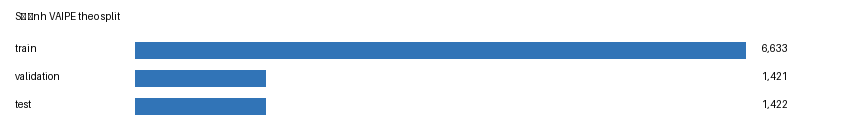

In [3]:
def bar_chart(items, title, width=850, row_height=28):
    items = list(items)
    height = 55 + len(items) * row_height
    canvas = Image.new("RGB", (width, height), "white")
    draw = ImageDraw.Draw(canvas)
    draw.text((15, 10), title, fill="black")
    maximum = max((value for _, value in items), default=1)
    for index, (name, value) in enumerate(items):
        y = 42 + index * row_height
        draw.text((15, y), str(name), fill="black")
        draw.rectangle((135, y, 135 + int((width - 240) * value / maximum), y + 16), fill="#3174b7")
        draw.text((width - 88, y), f"{value:,}", fill="black")
    return canvas

display(bar_chart([(name, len(rows)) for name, rows in splits.items()], "Số ảnh VAIPE theo split"))


## 2. Phân bố lớp VAIPE

Đếm số box theo nhãn trong từng split. Nhãn số là **ID dữ liệu**, không chứng minh thành phần hay tên thuốc. ID 107 có ảnh đại diện rất đa dạng nên không thuộc 7 lớp nhận diện đã duyệt.


Số lớp xuất hiện: 108
Lớp có mặt ở cả 3 split: 64


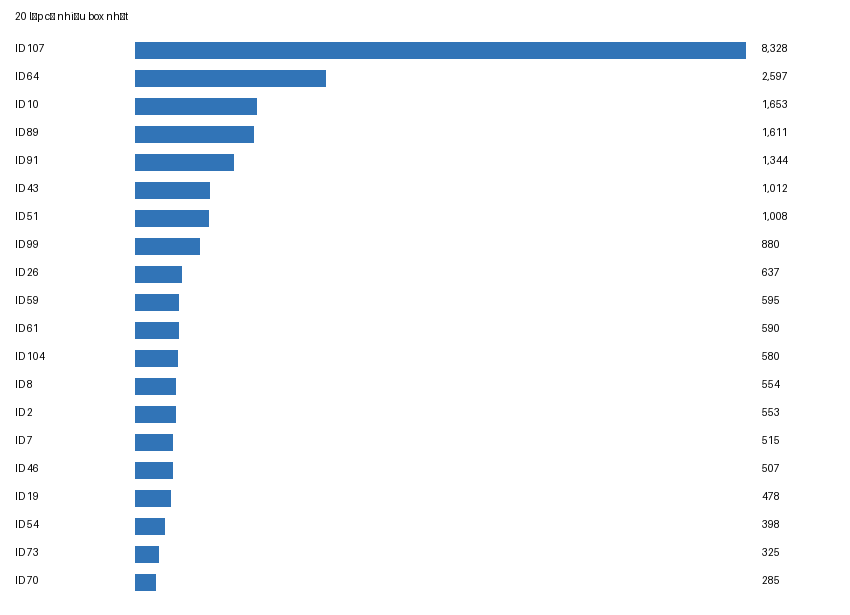

In [4]:
class_counts = {name: Counter() for name in splits}
for name, rows in splits.items():
    for row in rows:
        class_counts[name].update(json.loads(row["labels"]))
total_classes = sum(class_counts.values(), Counter())
print("Số lớp xuất hiện:", len(total_classes))
print("Lớp có mặt ở cả 3 split:", sum(all(class_counts[name][label] > 0 for name in splits) for label in total_classes))
display(bar_chart([(f"ID {label}", count) for label, count in total_classes.most_common(20)], "20 lớp có nhiều box nhất"))


In [5]:
candidate_rows = read_csv("model/reports/vaipe-demo-class-candidates.csv")
selected_labels = [64, 91, 89, 99, 51, 46, 10]  # Có thể đổi để khảo sát lớp khác
candidate_by_id = {int(row["label"]): row for row in candidate_rows}
print(f"{'ID':>4} {'Tổng box':>9} {'Train':>7} {'Val':>7} {'Test':>7} {'Nhóm':>6}")
for label in selected_labels:
    row = candidate_by_id[label]
    print(f"{label:4} {int(row['total_boxes']):9,} {int(row['train_boxes']):7,} {int(row['validation_boxes']):7,} {int(row['test_boxes']):7,} {int(row['group_count']):6,}")


  ID  Tổng box   Train     Val    Test   Nhóm
  64     2,597   1,831     352     414    249
  91     1,344     763     382     199    184
  89     1,611     842     374     395    161
  99       880     367     243     270     89
  51     1,008     597     230     181     92
  46       507     375      52      80     88
  10     1,653   1,012     313     328    175


## 3. Xem viên mẫu và bounding box

Chọn một ID và split. Mỗi ảnh minh họa được lấy từ nhóm chụp khác nhau; box được vẽ lên ảnh **sau khi xử lý EXIF orientation**, đúng hệ tọa độ của nhãn VAIPE.


VAIPE_P_168_46 | group 168 | boxes 1


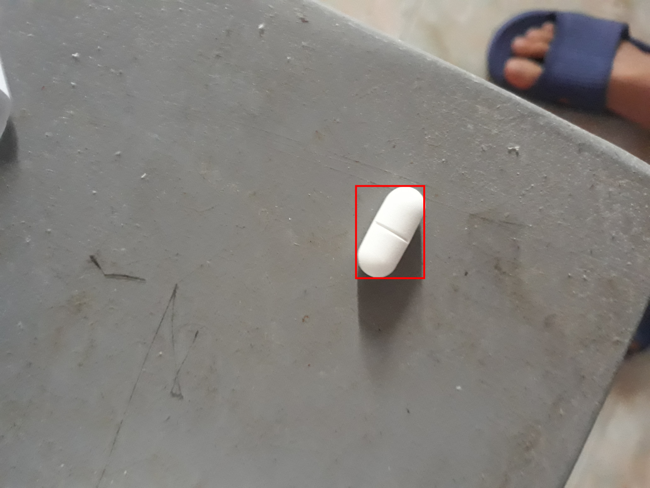

VAIPE_P_692_3 | group 692 | boxes 6


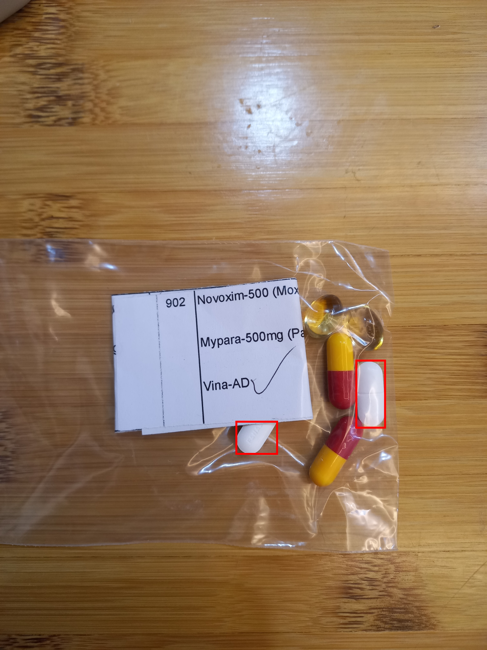

VAIPE_P_675_0 | group 675 | boxes 6


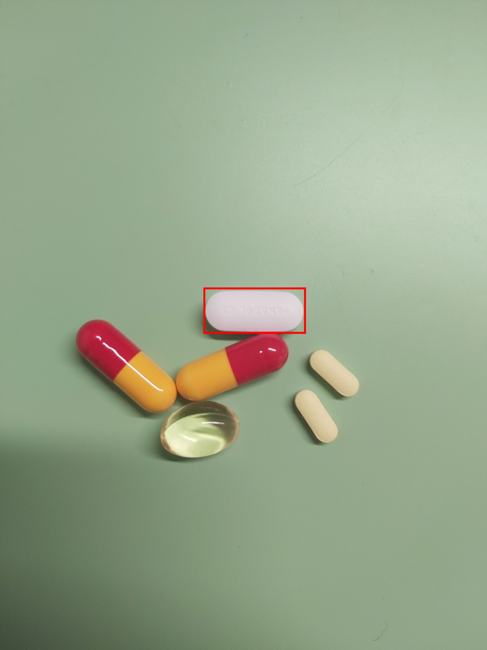

VAIPE_P_668_6 | group 668 | boxes 4


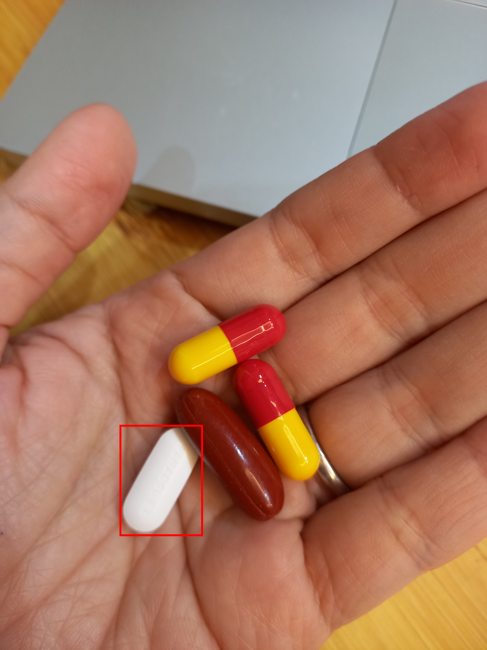

In [6]:
SAMPLE_LABEL = 89
SAMPLE_SPLIT = "train"
SAMPLE_COUNT = 4
SEED = 20261025

rng = random.Random(SEED)
options = [r for r in splits[SAMPLE_SPLIT] if SAMPLE_LABEL in json.loads(r["labels"])]
rng.shuffle(options)
chosen, seen_groups = [], set()
for row in options:
    if row["group_id"] in seen_groups:
        continue
    chosen.append(row)
    seen_groups.add(row["group_id"])
    if len(chosen) >= SAMPLE_COUNT:
        break

for row in chosen:
    with Image.open(ROOT / row["image_path"]) as source:
        image = ImageOps.exif_transpose(source).convert("RGB")
    boxes = json.loads((ROOT / row["label_path"]).read_text())
    draw = ImageDraw.Draw(image)
    for box in boxes:
        if box["label"] == SAMPLE_LABEL:
            x, y, w, h = (box[k] for k in ("x", "y", "w", "h"))
            draw.rectangle((x, y, x+w, y+h), outline="red", width=12)
    image.thumbnail((650, 650))
    print(row["image_id"], "| group", row["group_id"], "| boxes", len(boxes))
    display(image)


## 4. Các cặp đã loại

Danh sách này ghi **cả đường ảnh và đường nhãn** của mỗi cặp bị loại. Tệp gốc vẫn tồn tại trong `data/external/`; các split không chứa các cặp này.


In [7]:
reason_counts = Counter("unreadable_image" if "unreadable_image" in r["validation_errors"] else "invalid_label" for r in excluded)
print("Lý do:", dict(reason_counts))
for row in excluded[:10]:
    print(row["image_id"], "| ảnh:", Path(row["image_path"]).name, "| nhãn:", Path(row["label_path"]).name)
print(f"... tổng cộng {len(excluded)} cặp; xem CSV để có đủ lý do từng cặp.")


Lý do: {'invalid_label': 25, 'unreadable_image': 1}
VAIPE_P_1130_2 | ảnh: VAIPE_P_1130_2.jpg | nhãn: VAIPE_P_1130_2.json
VAIPE_P_1160_19 | ảnh: VAIPE_P_1160_19.jpg | nhãn: VAIPE_P_1160_19.json
VAIPE_P_128_6 | ảnh: VAIPE_P_128_6.jpg | nhãn: VAIPE_P_128_6.json
VAIPE_P_147_6 | ảnh: VAIPE_P_147_6.jpg | nhãn: VAIPE_P_147_6.json
VAIPE_P_185_12 | ảnh: VAIPE_P_185_12.jpg | nhãn: VAIPE_P_185_12.json
VAIPE_P_185_23 | ảnh: VAIPE_P_185_23.jpg | nhãn: VAIPE_P_185_23.json
VAIPE_P_185_24 | ảnh: VAIPE_P_185_24.jpg | nhãn: VAIPE_P_185_24.json
VAIPE_P_185_54 | ảnh: VAIPE_P_185_54.jpg | nhãn: VAIPE_P_185_54.json
VAIPE_P_208_8 | ảnh: VAIPE_P_208_8.jpg | nhãn: VAIPE_P_208_8.json
VAIPE_P_230_11 | ảnh: VAIPE_P_230_11.jpg | nhãn: VAIPE_P_230_11.json
... tổng cộng 26 cặp; xem CSV để có đủ lý do từng cặp.


## 5. PharmaVision: bình thường và lỗi

Bộ này có split riêng từ nguồn và không được chia lại. Xem số ảnh theo lớp và ảnh đại diện trước khi thiết kế thí nghiệm `normal/defective`.


train normal: 190 defective: 190
validation normal: 30 defective: 30
test normal: 100 defective: 100


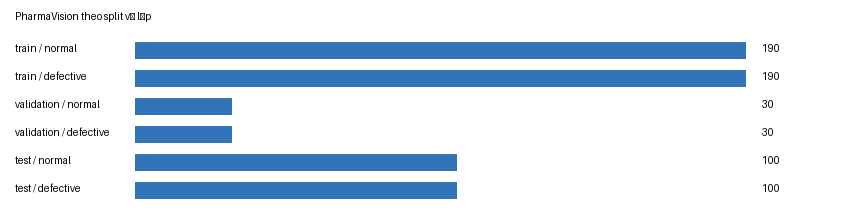

In [8]:
pharma_counts = Counter((r["split"], r["label"]) for r in pharma)
for split_name in ("train", "validation", "test"):
    print(split_name, "normal:", pharma_counts[split_name, "normal"], "defective:", pharma_counts[split_name, "defective"])
display(bar_chart([(f"{split_name} / {label}", pharma_counts[split_name, label]) for split_name in ("train", "validation", "test") for label in ("normal", "defective")], "PharmaVision theo split và lớp"))


normal


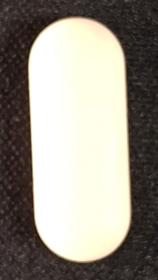

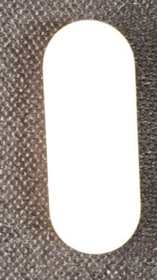

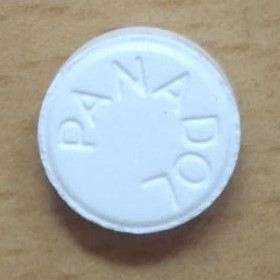

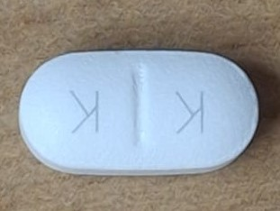

defective


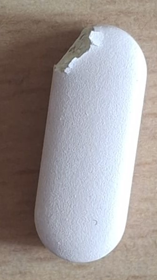

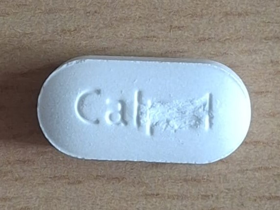

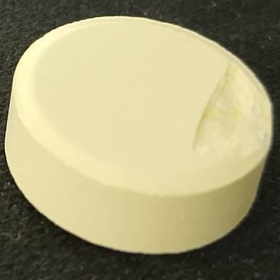

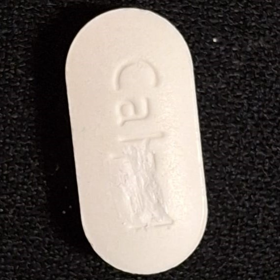

In [9]:
PHARMA_SPLIT = "train"
PHARMA_PER_CLASS = 4
rng = random.Random(SEED)
for label in ("normal", "defective"):
    choices = [r for r in pharma if r["split"] == PHARMA_SPLIT and r["label"] == label]
    print(label)
    for row in rng.sample(choices, min(PHARMA_PER_CLASS, len(choices))):
        with Image.open(ROOT / row["image_path"]) as source:
            image = ImageOps.exif_transpose(source).convert("RGB")
        image.thumbnail((280, 280))
        display(image)


## 6. Câu hỏi nên trả lời trước khi train

- Hai cặp gần giống 89/99 và 51/46 có phân biệt được từ **mặt camera sẽ nhìn thấy** không?
- Có lớp nào ảnh đại diện không nhất quán hoặc quá ít mẫu ở validation/test không?
- Ảnh từ camera và ánh sáng của máy demo khác ảnh VAIPE/PharmaVision đến mức nào?
- Bảy lớp nhận diện đã duyệt là 64, 91, 89, 99, 51, 46, 10. Giữ nguyên split hiện tại để benchmark công bằng.

Xem thêm `model/reports/data-foundation-summary.md` và `model/reports/vaipe-demo-contact-sheet.jpg`.
